# Clasificación de piezas para un robot de pick and place

Un robot recoge de una cinta piezas de fijación que llegan mezcladas y las tiene que dejar cada una en su caja. La cámara mira la cinta desde arriba con un panel de contraluz debajo, así que las piezas se ven oscuras sobre fondo claro. Hay cuatro clases: arandela, tuerca, tornillo y remache.

Las imágenes las genero con el script 01_generar_dataset.py, que las guarda en dataset/train y dataset/test con una carpeta por clase. En este cuaderno pruebo varios clasificadores, primero uno de prototipos sobre los píxeles, después el enfoque clásico con morfología y características, con distancia mínima y Bayes, y por último un perceptrón multicapa. Al final conecto el clasificador con el robot usando una imagen de la cinta con varias piezas.

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## 1. Dataset

Cargo todas las imágenes en escala de grises. Cada imagen es de 96x96 y la etiqueta es el número de la clase.

In [2]:
CLASES = ["arandela", "tuerca", "tornillo", "remache"]

def cargar(split):
    imgs = []
    etiquetas = []
    for k in range(len(CLASES)):
        carpeta = os.path.join("dataset", split, CLASES[k])
        for f in sorted(os.listdir(carpeta)):
            img = cv2.imread(os.path.join(carpeta, f), cv2.IMREAD_GRAYSCALE)
            imgs.append(img)
            etiquetas.append(k)
    return np.array(imgs), np.array(etiquetas)

X, y = cargar("train")
X_test, y_test = cargar("test")
print("train: ", X.shape)
print("test: ", X_test.shape)

train:  (800, 96, 96)
test:  (200, 96, 96)


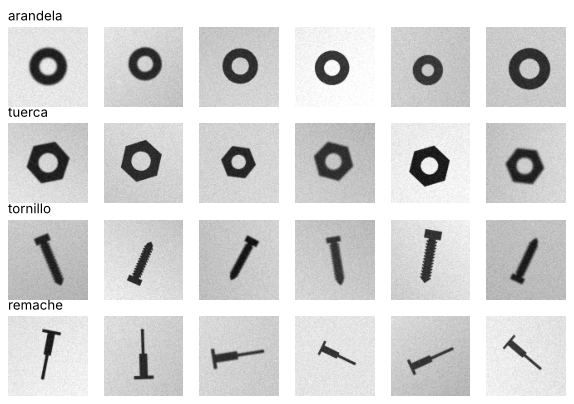

In [3]:
fig, ax = plt.subplots(4, 6, figsize=(9,6))
for k in range(4):
    ejemplos = X[y == k]
    for j in range(6):
        ax[k,j].imshow(ejemplos[j*20], cmap="gray", vmin=0, vmax=255)
        ax[k,j].axis('off')
    ax[k,0].set_title(CLASES[k], loc="left")
plt.show()

Para poder elegir y comparar los métodos sin tocar el test, separo un 20 % del train como validación. Así me quedan 160 imágenes por clase para entrenar, 40 para validar y las 50 del test, que son algo más difíciles porque tienen más ruido y desenfoque.

In [4]:
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
print("entrenamiento: ", len(X_tr))
print("validacion: ", len(X_val))
print("test: ", len(X_test))

entrenamiento:  640
validacion:  160
test:  200


## 2. Clasificador de prototipos con los píxeles

Primero pruebo lo más sencillo: el prototipo de cada clase es la media de sus imágenes de entrenamiento y cada imagen nueva se asigna a la clase cuyo prototipo está más cerca con la distancia euclídea, usando directamente los 96x96 píxeles.

Accuracy validacion:  0.625
Accuracy test:  0.515


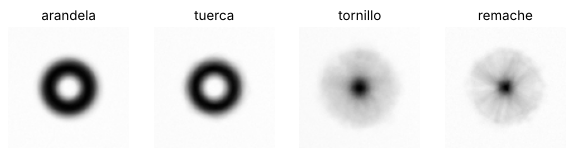

In [5]:
prototipos = []
for k in range(4):
    prototipos.append(X_tr[y_tr == k].reshape(-1, 96*96).mean(axis=0))

def predecir_prototipo(img):
    v = img.flatten().astype(float)
    distancias = [np.linalg.norm(v - p) for p in prototipos]
    return int(np.argmin(distancias))

fig, ax = plt.subplots(1, 4, figsize=(9,2.6))
for k in range(4):
    ax[k].imshow(prototipos[k].reshape(96,96), cmap="gray")
    ax[k].set_title(CLASES[k])
    ax[k].axis('off')
plt.show()

pred_proto_val = np.array([predecir_prototipo(img) for img in X_val])
pred_proto = np.array([predecir_prototipo(img) for img in X_test])
print("Accuracy validacion: ", round(accuracy_score(y_val, pred_proto_val), 3))
print("Accuracy test: ", round(accuracy_score(y_test, pred_proto), 3))

Como las piezas pueden estar giradas en cualquier ángulo, los prototipos del tornillo y del remache salen como una mancha redonda y los de la arandela y la tuerca casi iguales. Comparar píxel a píxel no aguanta los giros, así que hace falta describir las piezas con medidas que no cambien al girarlas.

## 3. Segmentación y morfología

Con la contraluz la pieza se separa bien del fondo, así que umbralizo con Otsu, invirtiendo para que la pieza quede en blanco, y hago una apertura con un elemento estructurante de 3x3 para quitar los puntos sueltos del ruido. Después saco el contorno con findContours.

umbral:  134.0
contornos:  2


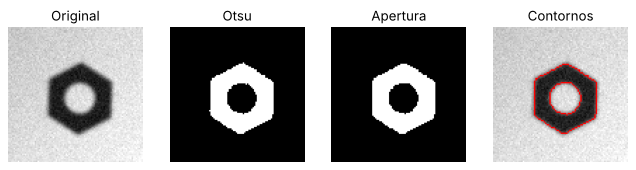

In [6]:
kernel = np.ones((3,3), np.uint8)

img = X_test[60]
t, bw = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
limpia = cv2.morphologyEx(bw, cv2.MORPH_OPEN, kernel)
contornos, jerarquia = cv2.findContours(limpia, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_NONE)
dibujo = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
cv2.drawContours(dibujo, contornos, -1, (255,0,0), 1)
print("umbral: ", t)
print("contornos: ", len(contornos))

fig, ax = plt.subplots(1, 4, figsize=(10,2.8))
ax[0].imshow(img, cmap="gray"); ax[0].set_title("Original")
ax[1].imshow(bw, cmap="gray"); ax[1].set_title("Otsu")
ax[2].imshow(limpia, cmap="gray"); ax[2].set_title("Apertura")
ax[3].imshow(dibujo); ax[3].set_title("Contornos")
for x in ax:
    x.axis('off')
plt.show()

## 4. Características

De cada pieza calculo:

-Área: número de píxeles de la pieza. Como la cámara está siempre a la misma altura, sirve para el tamaño.
-Circularidad: 4πA/P² con el área y el perímetro del contorno exterior. Vale casi 1 en la arandela y menos en la tuerca, y muy poco en las piezas alargadas.
-Número de agujeros: los contornos que están dentro del contorno exterior.
-Excentricidad: con los momentos centrales de segundo orden, √(1 − b²/a²), donde a y b son los ejes de la elipse equivalente. Casi 0 en las piezas redondas y casi 1 en las alargadas.
-Los dos primeros momentos de Hu, que no cambian al trasladar, girar o escalar la pieza. Los paso a escala logarítmica porque son números muy pequeños.

Todas salvo el área son invariantes al giro, que era el problema de los prototipos.

In [7]:
def segmentar(img):
    t, bw = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    return cv2.morphologyEx(bw, cv2.MORPH_OPEN, kernel)

def caracteristicas(bw):
    contornos, jerarquia = cv2.findContours(bw, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_NONE)
    exteriores = [i for i in range(len(contornos)) if jerarquia[0][i][3] == -1]
    i = max(exteriores, key=lambda j: cv2.contourArea(contornos[j]))
    pieza = np.zeros_like(bw)
    cv2.drawContours(pieza, contornos, i, 255, -1)
    for j in range(len(contornos)):
        if jerarquia[0][j][3] == i:
            cv2.drawContours(pieza, contornos, j, 0, -1)

    area = np.count_nonzero(pieza)
    perimetro = cv2.arcLength(contornos[i], True)
    circularidad = 4 * np.pi * cv2.contourArea(contornos[i]) / perimetro**2
    agujeros = sum(1 for j in range(len(contornos)) if jerarquia[0][j][3] == i)

    m = cv2.moments(pieza, binaryImage=True)
    mu20 = m["mu20"] / m["m00"]
    mu02 = m["mu02"] / m["m00"]
    mu11 = m["mu11"] / m["m00"]
    a2 = (mu20 + mu02) / 2 + np.sqrt(((mu20 - mu02) / 2)**2 + mu11**2)
    b2 = (mu20 + mu02) / 2 - np.sqrt(((mu20 - mu02) / 2)**2 + mu11**2)
    excentricidad = np.sqrt(1 - b2 / a2)

    hu = cv2.HuMoments(m).flatten()
    hu1 = -np.log10(abs(hu[0]))
    hu2 = -np.log10(abs(hu[1]))
    return [area, circularidad, agujeros, excentricidad, hu1, hu2]

NOMBRES = ["area", "circularidad", "agujeros", "excentricidad", "hu1", "hu2"]

F_tr = np.array([caracteristicas(segmentar(img)) for img in X_tr])
F_val = np.array([caracteristicas(segmentar(img)) for img in X_val])
F_test = np.array([caracteristicas(segmentar(img)) for img in X_test])
print(F_tr.shape, F_val.shape, F_test.shape)

(640, 6) (160, 6) (200, 6)


In [8]:
for k in range(4):
    print(CLASES[k])
    medias = F_tr[y_tr == k].mean(axis=0)
    for n in range(len(NOMBRES)):
        print("  ", NOMBRES[n], round(medias[n], 3))

arandela
   area 1175.912
   circularidad 0.894
   agujeros 1.0
   excentricidad 0.094
   hu1 0.591
   hu2 5.981
tuerca
   area 1029.85
   circularidad 0.833
   agujeros 1.0
   excentricidad 0.141
   hu1 0.55
   hu2 5.196
tornillo
   area 659.506
   circularidad 0.312
   agujeros 0.0
   excentricidad 0.978
   hu1 0.323
   hu2 0.72
remache
   area 395.356
   circularidad 0.19
   agujeros 0.0
   excentricidad 0.979
   hu1 0.203
   hu2 0.479


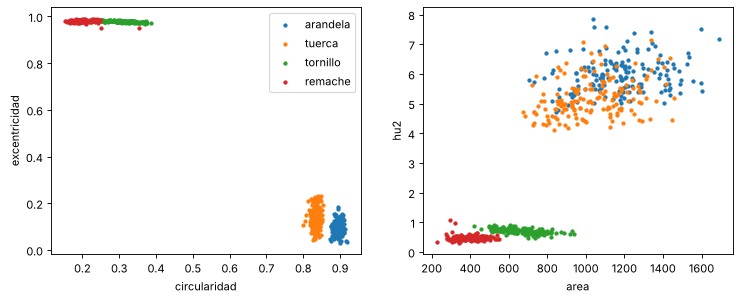

In [9]:
colores = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
fig, ax = plt.subplots(1, 2, figsize=(11,4))
for k in range(4):
    ax[0].scatter(F_tr[y_tr == k, 1], F_tr[y_tr == k, 3], s=8, color=colores[k], label=CLASES[k])
    ax[1].scatter(F_tr[y_tr == k, 0], F_tr[y_tr == k, 5], s=8, color=colores[k], label=CLASES[k])
ax[0].set_xlabel("circularidad")
ax[0].set_ylabel("excentricidad")
ax[1].set_xlabel("area")
ax[1].set_ylabel("hu2")
ax[0].legend()
plt.show()

En la primera gráfica las piezas redondas quedan abajo a la derecha y las alargadas arriba a la izquierda, pero la arandela y la tuerca están muy juntas, igual que el tornillo y el remache. En la segunda el área separa bastante bien el tornillo del remache, que es más fino. Por eso conviene usar todas las características juntas.

Antes de clasificar normalizo cada característica restando la media y dividiendo por la desviación típica del entrenamiento, para que el área, que va por los miles, no pese más que el resto.

In [10]:
media = F_tr.mean(axis=0)
desv = F_tr.std(axis=0)
Z_tr = (F_tr - media) / desv
Z_val = (F_val - media) / desv
Z_test = (F_test - media) / desv

## 5. Distancia mínima y Bayes con las características

El clasificador de distancia mínima es el mismo que el de prototipos, pero ahora el prototipo de cada clase es la media de su vector de características. El de Bayes supone que cada característica sigue una normal en cada clase y elige la clase con más probabilidad, que es el clasificador estadístico óptimo si se cumple esa suposición.

In [11]:
centros = [Z_tr[y_tr == k].mean(axis=0) for k in range(4)]

def distancia_minima(z):
    return int(np.argmin([np.linalg.norm(z - c) for c in centros]))

pred_dm_val = np.array([distancia_minima(z) for z in Z_val])
pred_dm = np.array([distancia_minima(z) for z in Z_test])
print("Distancia minima validacion: ", round(accuracy_score(y_val, pred_dm_val), 3))
print("Distancia minima test: ", round(accuracy_score(y_test, pred_dm), 3))

bayes = GaussianNB()
bayes.fit(Z_tr, y_tr)
pred_bayes_val = bayes.predict(Z_val)
pred_bayes = bayes.predict(Z_test)
prob_bayes = bayes.predict_proba(Z_test)
print("Bayes validacion: ", round(accuracy_score(y_val, pred_bayes_val), 3))
print("Bayes test: ", round(accuracy_score(y_test, pred_bayes), 3))

Distancia minima validacion:  0.825
Distancia minima test:  0.79
Bayes validacion:  1.0
Bayes test:  0.995


## 6. Perceptrón multicapa

Para comparar con una red neuronal entreno un perceptrón multicapa. Primero con los píxeles directamente, como el MLP de base, con una capa oculta de 256 neuronas y early stopping, que guarda un 10 % del entrenamiento para validar en cada época y para cuando lleva 30 épocas sin mejorar. Después con las características, con una capa oculta de 32 neuronas. Aquí no uso early stopping porque con tan pocos datos esa validación interna es muy pequeña y paraba demasiado pronto, así que lo dejo entrenar hasta que converge y lo valido con mi conjunto de validación.

In [12]:
P_tr = X_tr.reshape(len(X_tr), -1) / 255
P_val = X_val.reshape(len(X_val), -1) / 255
P_test = X_test.reshape(len(X_test), -1) / 255

mlp = MLPClassifier(hidden_layer_sizes=(256,), early_stopping=True, n_iter_no_change=30, max_iter=500, random_state=0)
mlp.fit(P_tr, y_tr)
pred_mlp_val = mlp.predict(P_val)
pred_mlp = mlp.predict(P_test)
print("Epocas: ", mlp.n_iter_)
print("MLP pixeles validacion: ", round(accuracy_score(y_val, pred_mlp_val), 3))
print("MLP pixeles test: ", round(accuracy_score(y_test, pred_mlp), 3))

mlp2 = MLPClassifier(hidden_layer_sizes=(32,), max_iter=2000, random_state=0)
mlp2.fit(Z_tr, y_tr)
pred_mlp2_val = mlp2.predict(Z_val)
pred_mlp2 = mlp2.predict(Z_test)
print("MLP caracteristicas validacion: ", round(accuracy_score(y_val, pred_mlp2_val), 3))
print("MLP caracteristicas test: ", round(accuracy_score(y_test, pred_mlp2), 3))

Epocas:  76
MLP pixeles validacion:  0.787
MLP pixeles test:  0.8
MLP caracteristicas validacion:  0.994
MLP caracteristicas test:  0.985


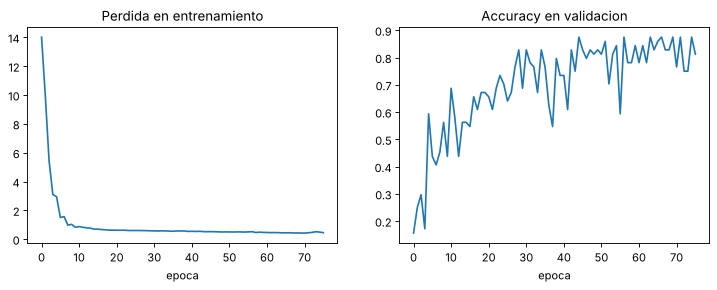

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11,3.5))
ax[0].plot(mlp.loss_curve_)
ax[0].set_title("Perdida en entrenamiento")
ax[0].set_xlabel("epoca")
ax[1].plot(mlp.validation_scores_)
ax[1].set_title("Accuracy en validacion")
ax[1].set_xlabel("epoca")
plt.show()

## 7. Comparación y resultados en test

In [14]:
nombres = ["Prototipos pixeles", "Distancia minima caract.", "Bayes caract.", "MLP pixeles", "MLP caract."]
val = [pred_proto_val, pred_dm_val, pred_bayes_val, pred_mlp_val, pred_mlp2_val]
test = [pred_proto, pred_dm, pred_bayes, pred_mlp, pred_mlp2]
for i in range(len(nombres)):
    print(nombres[i], " validacion: ", round(accuracy_score(y_val, val[i]), 3), " test: ", round(accuracy_score(y_test, test[i]), 3))

Prototipos pixeles  validacion:  0.625  test:  0.515
Distancia minima caract.  validacion:  0.825  test:  0.79
Bayes caract.  validacion:  1.0  test:  0.995
MLP pixeles  validacion:  0.787  test:  0.8
MLP caract.  validacion:  0.994  test:  0.985


              precision    recall  f1-score   support

    arandela      1.000     0.980     0.990        50
      tuerca      0.980     1.000     0.990        50
    tornillo      1.000     1.000     1.000        50
     remache      1.000     1.000     1.000        50

    accuracy                          0.995       200
   macro avg      0.995     0.995     0.995       200
weighted avg      0.995     0.995     0.995       200



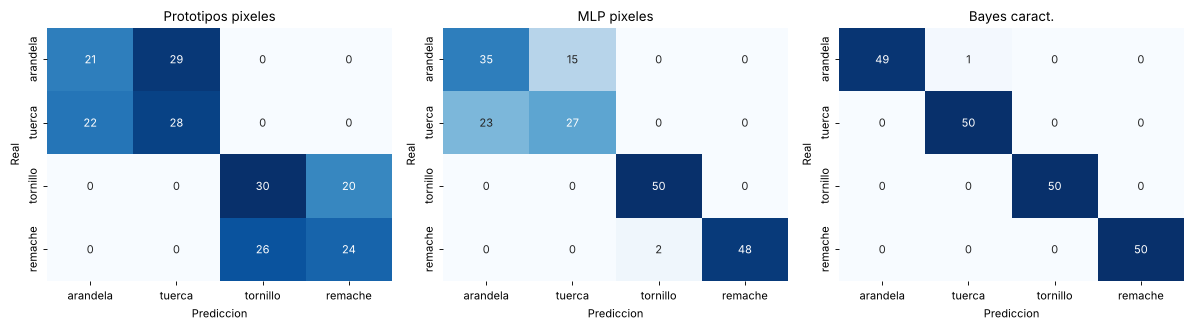

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(15,4.2))
for i, (n, p) in enumerate([("Prototipos pixeles", pred_proto), ("MLP pixeles", pred_mlp), ("Bayes caract.", pred_bayes)]):
    cm = confusion_matrix(y_test, p)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASES, yticklabels=CLASES, cbar=False, ax=ax[i])
    ax[i].set_title(n)
    ax[i].set_xlabel("Prediccion")
    ax[i].set_ylabel("Real")
plt.tight_layout()
plt.show()

print(classification_report(y_test, pred_bayes, target_names=CLASES, digits=3))

Los prototipos con los píxeles solo aciertan la mitad del test: confunden la arandela con la tuerca y el tornillo con el remache, que es justo lo que se veía en los prototipos. La distancia mínima con las características sube al 79 %, pero sigue confundiendo la arandela con la tuerca, porque trata todas las características igual y el área de las dos varía mucho. Bayes llega al 99,5 % porque tiene en cuenta la varianza de cada característica en cada clase, y la circularidad y el segundo momento de Hu, que separan la arandela de la tuerca, varían muy poco dentro de cada clase.

El MLP con los píxeles llega al 80 %. Distingue bien las piezas alargadas de las redondas, pero no la arandela de la tuerca, y su curva de validación sube y baja bastante. Con las características el mismo tipo de red llega al 98,5 %, casi como Bayes, así que lo que más importa aquí son las características y no tanto el clasificador.

## 8. Aciertos y errores

Me quedo con Bayes con las características, que es el que mejor va en validación, con un 100 %, y además da la probabilidad de cada clase, que me sirve para el robot. Muestro algunos aciertos con la clase predicha y su probabilidad, y todos los errores del test.

aciertos:  199
errores:  1


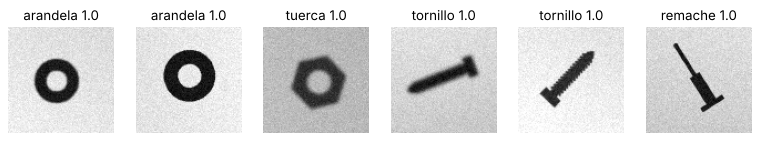

In [16]:
aciertos = np.where(pred_bayes == y_test)[0]
errores = np.where(pred_bayes != y_test)[0]
print("aciertos: ", len(aciertos))
print("errores: ", len(errores))

fig, ax = plt.subplots(1, 6, figsize=(12,2.6))
for j in range(6):
    i = aciertos[j * 33]
    ax[j].imshow(X_test[i], cmap="gray", vmin=0, vmax=255)
    ax[j].set_title(CLASES[pred_bayes[i]] + " " + str(round(prob_bayes[i].max(), 2)))
    ax[j].axis('off')
plt.show()

arandela -> tuerca  prob: 0.985  area: 1112  circ: 0.86  agujeros: 1


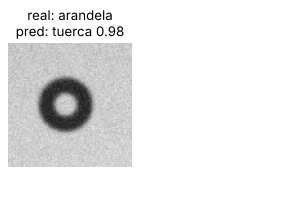

In [17]:
n = min(len(errores), 10)
fig, ax = plt.subplots(1, max(n, 2), figsize=(2.2 * max(n, 2), 2.8))
for j in range(n):
    i = errores[j]
    ax[j].imshow(X_test[i], cmap="gray", vmin=0, vmax=255)
    ax[j].set_title("real: " + CLASES[y_test[i]] + "\npred: " + CLASES[pred_bayes[i]] + " " + str(round(prob_bayes[i].max(), 2)))
for x in ax:
    x.axis('off')
plt.show()

for i in errores:
    print(CLASES[y_test[i]], "->", CLASES[pred_bayes[i]], " prob:", round(prob_bayes[i].max(), 3), " area:", int(F_test[i][0]), " circ:", round(F_test[i][1], 3), " agujeros:", int(F_test[i][2]))

## 9. Conexión con el robot

La imagen escena.png es un tramo de la cinta con varias piezas. Para cada pieza el sistema tiene que dar al robot la clase, la posición del centro y el ángulo para girar la pinza, y la caja donde dejarla. Separo las piezas con Otsu, apertura y componentes conexas, recorto una ventana de 96x96 alrededor de cada una, calculo las características y la clasifico con Bayes.

Si la probabilidad es menor de 0,9 o el área se sale del rango que había en el entrenamiento, la pieza no se coge y sigue hasta la caja de revisión. Esto pasa por ejemplo cuando dos piezas se tocan y salen como una sola. Supongo que la cámara está calibrada a 0,4 mm por píxel.

pieza 1  x: 93.6 mm  y: 29.5 mm  angulo: -69  prob: 1.0  area: 668  -> coger tornillo y dejar en caja 3
pieza 2  x: 223.3 mm  y: 33.8 mm  angulo: -28  prob: 1.0  area: 376  -> coger remache y dejar en caja 4
pieza 3  x: 32.5 mm  y: 36.7 mm  angulo: -35  prob: 1.0  area: 902  -> coger tuerca y dejar en caja 2
pieza 4  x: 160.9 mm  y: 38.8 mm  angulo: 81  prob: 1.0  area: 792  -> coger arandela y dejar en caja 1
pieza 5  x: 126.4 mm  y: 80.4 mm  angulo: 4  prob: 1.0  area: 2285  -> REVISION: no se coge
pieza 6  x: 32.6 mm  y: 104.2 mm  angulo: -24  prob: 1.0  area: 312  -> coger remache y dejar en caja 4
pieza 7  x: 165.9 mm  y: 117.1 mm  angulo: -33  prob: 1.0  area: 658  -> coger tornillo y dejar en caja 3
pieza 8  x: 223.1 mm  y: 119.3 mm  angulo: -60  prob: 1.0  area: 1075  -> coger tuerca y dejar en caja 2
pieza 9  x: 92.4 mm  y: 119.9 mm  angulo: 47  prob: 1.0  area: 843  -> coger arandela y dejar en caja 1


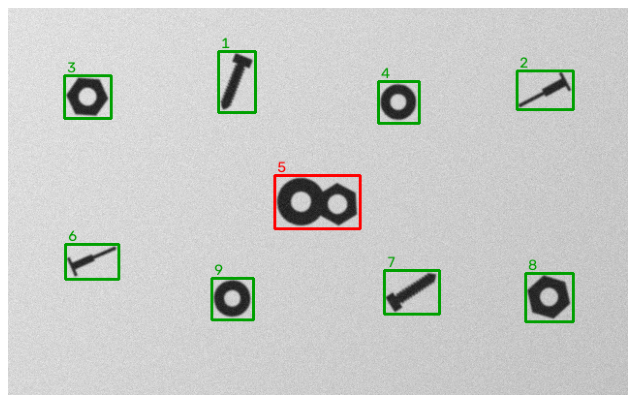

In [18]:
escena = cv2.imread("escena.png", cv2.IMREAD_GRAYSCALE)
bw_escena = segmentar(escena)
n, etiquetas, stats, centroides = cv2.connectedComponentsWithStats(bw_escena)

area_min = F_tr[:, 0].min()
area_max = F_tr[:, 0].max()
cajas = {"arandela": 1, "tuerca": 2, "tornillo": 3, "remache": 4}
mm_px = 0.4

resultado = cv2.cvtColor(escena, cv2.COLOR_GRAY2RGB)
for i in range(1, n):
    if stats[i, cv2.CC_STAT_AREA] < 100:
        continue
    cx, cy = centroides[i]
    pieza = np.uint8(etiquetas == i) * 255
    x0 = int(cx) - 48
    y0 = int(cy) - 48
    recorte = np.zeros((96,96), np.uint8)
    trozo = pieza[max(y0,0):y0+96, max(x0,0):x0+96]
    recorte[max(-y0,0):max(-y0,0)+trozo.shape[0], max(-x0,0):max(-x0,0)+trozo.shape[1]] = trozo

    f = np.array(caracteristicas(recorte))
    z = (f - media) / desv
    prob = bayes.predict_proba([z])[0]
    clase = CLASES[int(np.argmax(prob))]

    m = cv2.moments(pieza, binaryImage=True)
    angulo = 0.5 * np.degrees(np.arctan2(2 * m["mu11"], m["mu20"] - m["mu02"]))

    if prob.max() < 0.9 or f[0] < 0.9 * area_min or f[0] > 1.1 * area_max:
        orden = "REVISION: no se coge"
        color = (255, 0, 0)
    else:
        orden = "coger " + clase + " y dejar en caja " + str(cajas[clase])
        color = (0, 160, 0)
    print("pieza", i, " x:", round(cx * mm_px, 1), "mm  y:", round(cy * mm_px, 1), "mm  angulo:", round(angulo), " prob:", round(prob.max(), 3), " area:", int(f[0]), " ->", orden)

    px, py, w, h = stats[i, 0], stats[i, 1], stats[i, 2], stats[i, 3]
    cv2.rectangle(resultado, (px - 3, py - 3), (px + w + 3, py + h + 3), color, 2)
    cv2.putText(resultado, str(i), (px, py - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)

plt.figure(figsize=(10,6.5))
plt.imshow(resultado)
plt.axis('off')
plt.show()

## Conclusiones

Los prototipos con los píxeles fallan porque no aguantan los giros de las piezas. Con la contraluz, una umbralización con Otsu y una apertura, unas pocas características invariantes bastan para separar las cuatro clases casi sin errores, y el clasificador de Bayes además da una probabilidad que sirve para decidir si el robot coge la pieza o la manda a revisión. El perceptrón multicapa con los píxeles tiene que aprender él solo que una pieza girada sigue siendo la misma, y con tan pocas imágenes no lo consigue del todo. En la escena de la cinta el sistema acierta las ocho piezas sueltas y manda a revisión las dos que se tocan, aunque Bayes las daba con probabilidad 1, así que el control del área es necesario. La mayor limitación es que las piezas tienen que llegar separadas.